In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Conv1D, Dense, Flatten, Dropout, MaxPooling1D, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt
from larq.layers import QuantConv1D, QuantDense
from larq.models import summary
import larq_compute_engine as lce
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
import numpy as np
import scipy.io
import joblib
import numpy as np
import pandas as pd
from tabulate import tabulate

2025-03-12 13:03:06.014533: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-12 13:03:06.038650: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-12 13:03:06.038671: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-12 13:03:06.038683: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-12 13:03:06.043799: I tensorflow/core/platform/cpu_feature_g

In [3]:
# Check if GPU is Available
print("Num GPUs Available: ", tf.config.list_physical_devices('GPU'))
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    # Print information about each GPU
    for gpu in gpus:
        print("GPU:", gpu.name)
else:
    print("No GPU devices found.")

Num GPUs Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU: /physical_device:GPU:0


2025-03-12 13:03:07.728917: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:07.735105: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:07.735130: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## Dataset Preparation

In [4]:
def dataset(classes, val=True, window_length=5000, seed=42):
    seed = random.randint(0, 1000) if seed is None else seed
    if classes is None:
        raise ValueError("Classes cannot be None.")
    
    class_paths = []
    for classNum in classes:
        class_paths.append('./DatasetPDT/' + classNum + '/avt/')
    print(class_paths)

    ts_len = 65536

    # Load data
    ts_list = []
    labels_list = []
    for class_path in class_paths:
        print(class_path)
        for path in os.listdir(class_path):
            if path.endswith(".mat"):
                mat = scipy.io.loadmat(class_path + path)
                data = mat['data']
                data = data.T

                for i in range(len(data)):
                    # Check if length of timeserie is less than ts_len
                    if len(data[i]) < ts_len:
                        np_data = np.array(data[i])
                        last_value = np_data[-1]
                        # Concatenate the last value until ts_len
                        additional_values = np.full(ts_len - len(np_data), last_value)
                        np_data = np.concatenate((np_data, additional_values))
                        # Add to data
                        ts_list.append(np.array(np_data))
                    else:
                        # Add directly to data
                        ts_list.append(np.array(data[i]))
                    # Add label
                    labels_list.append(class_paths.index(class_path))

    # Combine dataset and labels for shuffling
    combined_data = list(zip(ts_list, labels_list))
    # Shuffle the combined data
    shuffled_data = shuffle(combined_data, random_state=seed)
    combined_data = None
    # Split the shuffled data back into dataset and labels
    shuffled_dataset, shuffled_labels = zip(*shuffled_data)
    shuffled_dataset = np.array(shuffled_dataset)
    shuffled_labels = np.array(shuffled_labels)

    scaler = StandardScaler()
    # Fit the scaler on the training data and transform both training and validation data
    scaled_dataset = scaler.fit_transform(shuffled_dataset.reshape(-1, ts_len)).reshape(shuffled_dataset.shape)

    combined_data = list(zip(scaled_dataset, shuffled_labels))
    train_data, test_data, val_data = [], [], []

    for class_label in range(len(classes)):
        class_data, class_labels = zip(*[(data, label) for data, label in combined_data if label == class_label])
        train, test, ytrain, ytest = train_test_split(class_data, class_labels, test_size=1/5, random_state=seed)
        train, valid, ytrain, yval = train_test_split(train, ytrain, test_size=1/8, random_state=seed)
        train_data.extend(zip(train, ytrain))
        test_data.extend(zip(test, ytest))
        val_data.extend(zip(valid, yval))

    # Unzip and convert the data into numpy arrays
    X_train_pre, y_train_pre = map(np.array, zip(*train_data))
    X_test_pre, y_test_pre = map(np.array, zip(*test_data))
    X_val_pre, y_val_pre = map(np.array, zip(*val_data))

    X_train_pre = np.array(X_train_pre)
    X_test_pre = np.array(X_test_pre)
    X_val_pre = np.array(X_val_pre)
    y_train_pre = np.array(y_train_pre)
    y_test_pre = np.array(y_test_pre)
    y_val_pre = np.array(y_val_pre)

    def create_windows(data_array, label_array, window_length):
        X, y = [], []
        for i in range(len(data_array)):
            for start in range(0, len(data_array[i]) - window_length + 1, window_length):
                end = start + window_length
                X.append(data_array[i][start:end])
                y.append(label_array[i])
        return X, y

    X_train, y_train = create_windows(X_train_pre, y_train_pre, window_length)
    X_val, y_val = create_windows(X_val_pre, y_val_pre, window_length)
    X_test, y_test = create_windows(X_test_pre, y_test_pre, window_length)
    
    width = len(X_train[0])
 
    # Assuming X_train, X_valid, and X_test are 2D arrays with shape (number_of_samples, sequence_length)
    X_train = np.array([np.array(x) for x in X_train])
    X_val = np.array([np.array(x) for x in X_val])
    X_test = np.array([np.array(x) for x in X_test])
    
    # Reshape the input data to have a third dimension
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1) 
    X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)     
    X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

    print(X_train.shape, X_val.shape, X_test.shape)   
    
    X_train = tf.convert_to_tensor(X_train, dtype=tf.float32)
    y_train = tf.convert_to_tensor(y_train, dtype=tf.float32)
    X_val = tf.convert_to_tensor(X_val, dtype=tf.float32)
    y_val = tf.convert_to_tensor(y_val, dtype=tf.float32)
    X_test = tf.convert_to_tensor(X_test, dtype=tf.float32)
    y_test = tf.convert_to_tensor(y_test, dtype=tf.float32)
    
    return X_train, X_val, X_test, y_train, y_val, y_test, width

In [5]:
classes = ['01','03','04','05', '06','07','09','10','11', '12','13','14','15','16','17']
X_train, X_val, X_test, y_train, y_val, y_test, width = dataset(classes, val=True, window_length=65536)

['./DatasetPDT/01/avt/', './DatasetPDT/03/avt/', './DatasetPDT/04/avt/', './DatasetPDT/05/avt/', './DatasetPDT/06/avt/', './DatasetPDT/07/avt/', './DatasetPDT/09/avt/', './DatasetPDT/10/avt/', './DatasetPDT/11/avt/', './DatasetPDT/12/avt/', './DatasetPDT/13/avt/', './DatasetPDT/14/avt/', './DatasetPDT/15/avt/', './DatasetPDT/16/avt/', './DatasetPDT/17/avt/']
./DatasetPDT/01/avt/
./DatasetPDT/03/avt/
./DatasetPDT/04/avt/
./DatasetPDT/05/avt/
./DatasetPDT/06/avt/
./DatasetPDT/07/avt/
./DatasetPDT/09/avt/
./DatasetPDT/10/avt/
./DatasetPDT/11/avt/
./DatasetPDT/12/avt/
./DatasetPDT/13/avt/
./DatasetPDT/14/avt/
./DatasetPDT/15/avt/
./DatasetPDT/16/avt/
./DatasetPDT/17/avt/
(3021, 65536, 1) (432, 65536, 1) (877, 65536, 1)


2025-03-12 13:03:25.683692: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:25.683753: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:25.683763: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:25.958481: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-12 13:03:25.958549: I tensorflow/compile

## NN Evaluation Methods

In [6]:
def evaluate_NN_models(model_list, X_test, y_test):
    loss, accuracy, y_pred, precision, recall, f1_score, support, confusion_matrix_list = [], [], [], [], [], [], [], []
    for model in model_list:
        loss_value, accuracy_value = model.evaluate(X_test, y_test)
        loss.append(loss_value)
        accuracy.append(accuracy_value)
        y_pred_value = np.argmax(model.predict(X_test), axis=1)
        y_pred.append(y_pred_value)
        y_test_classes = y_test
        precision_value, recall_value, f1_score_value, support_value = precision_recall_fscore_support(y_test_classes, y_pred_value, average='weighted')
        precision.append(precision_value)
        recall.append(recall_value)
        f1_score.append(f1_score_value)
        support.append(support_value)
        confusion_matrix_value = confusion_matrix(y_test_classes, y_pred_value)
        confusion_matrix_list.append(confusion_matrix_value)
    return [accuracy, precision, recall, f1_score], confusion_matrix_list, y_pred

In [7]:
def print_table(data,headers):
    table_data = list(zip(*data))
    table = tabulate(table_data, headers=headers, tablefmt='grid')
    print(table)

In [8]:
def plot_confusion_matrix(ax, conf_matrix, title, cmap):
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax)
    ax.set_title(title)

In [9]:
def draw_confusion_matrix(matrix,name):
    colormap=["Blues","Greens","Oranges"]
    fig, axes = plt.subplots(1, 1, figsize=(15, 5))
    for i in range(len(matrix)):
        plot_confusion_matrix(axes, matrix[i], "Confusion Matrix  ", colormap[i])
    plt.tight_layout()

## Hyperparameters Optimization

In [10]:
class BinaryNetHyperModel(kt.HyperModel):
    def __init__(self, input_shape, num_classes):
        self.input_shape = input_shape
        self.num_classes = num_classes

    def build(self, hp):
        kwargs = dict(input_quantizer="ste_sign",
                     kernel_quantizer="ste_sign",
                     kernel_constraint="weight_clip")

        model = Sequential()
        
        # Tune the first Conv1D layer
        filters_conv1 = hp.Int('conv1_filters', min_value=16, max_value=64, step=16)
        model.add(Conv1D(filters=filters_conv1, kernel_size=3, activation='relu', 
                        input_shape=self.input_shape))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))

        # Tune the first QuantConv1D layer
        filters_qconv1 = hp.Int('qconv1_filters', min_value=4, max_value=16, step=4)
        model.add(QuantConv1D(filters_qconv1, kernel_size=3,
                             kernel_quantizer="ste_sign",
                             kernel_constraint="weight_clip",
                             use_bias=False))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))
        model.add(Dropout(rate=hp.Float('dropout1', min_value=0.2, max_value=0.5)))

        # Tune the second QuantConv1D layer
        filters_qconv2 = hp.Int('qconv2_filters', min_value=4, max_value=16, step=4)
        model.add(QuantConv1D(filters_qconv2, kernel_size=3, use_bias=False, **kwargs))
        model.add(MaxPooling1D(pool_size=2))
        model.add(BatchNormalization(scale=False))
        model.add(Dropout(rate=hp.Float('dropout2', min_value=0.2, max_value=0.5)))

        model.add(Flatten())

        # Tune the QuantDense layer
        units_qdense = hp.Int('qdense_units', min_value=4, max_value=16, step=4)
        model.add(QuantDense(units_qdense, use_bias=False, **kwargs))
        model.add(BatchNormalization(scale=False))
        model.add(Dense(self.num_classes, activation='softmax'))

        # Tune learning rate
        learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')
        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        return model

In [11]:
# Initialize the hypermodel
hypermodel = BinaryNetHyperModel(input_shape=(width, 1), num_classes=len(classes))

# Create the tuner
tuner = kt.BayesianOptimization(
    hypermodel,
    objective='val_accuracy',
    max_trials=20,
    directory='bayesian_opt',
    project_name='z24_tuning'
)

# Define early stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=50,
    verbose=1,
    mode='min',
    restore_best_weights=True
)

# Search for the best hyperparameters
tuner.search(
    X_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping]
)

# Get the best hyperparameters
best_hps_list = tuner.get_best_hyperparameters(num_trials=3)

Trial 20 Complete [00h 22m 04s]
val_accuracy: 0.9976851940155029

Best val_accuracy So Far: 1.0
Total elapsed time: 04h 45m 39s


In [13]:
# Build and evaluate the top 3 models
models = []
scores = []

print("\nTop 3 Models Performance:")
print("-" * 50)

for idx, hps in enumerate(best_hps_list, 1):
    print(f"\nModel {idx}:")
    print("Hyperparameters:")
    for param, value in hps.values.items():
        print(f"{param}: {value}")
            
    # Build and evaluate the model
    model = tuner.hypermodel.build(hps)
    model.fit(X_train, y_train, 
             epochs=10,  # Quick evaluation
             batch_size=32,
             validation_data=(X_val, y_val),
             verbose=0)
    
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print(f"Validation Accuracy: {val_acc:.4f}")
    
    models.append(model)
    scores.append(val_acc)
        
# Let user choose the model
while True:
    try:
        choice = int(input("\nChoose a model (1, 2, or 3): "))
        if 1 <= choice <= 3:
            break
        print("Please enter 1, 2, or 3")
    except ValueError:
        print("Please enter a valid number")

# Use the chosen model
model = models[choice - 1]
chosen_hps = best_hps_list[choice - 1]

print(f"\nSelected Model {choice}")
print("Final hyperparameters:")
for param, value in chosen_hps.values.items():
    print(f"{param}: {value}")


Top 3 Models Performance:
--------------------------------------------------

Model 1:
Hyperparameters:
conv1_filters: 16
qconv1_filters: 16
dropout1: 0.40620962667799854
qconv2_filters: 12
dropout2: 0.42247310240461755
qdense_units: 8
learning_rate: 0.0005290651376327243
Validation Accuracy: 0.7083

Model 2:
Hyperparameters:
conv1_filters: 32
qconv1_filters: 12
dropout1: 0.40666209711611456
qconv2_filters: 4
dropout2: 0.40673162558240916
qdense_units: 12
learning_rate: 0.0005276965876741727
Validation Accuracy: 0.1736

Model 3:
Hyperparameters:
conv1_filters: 32
qconv1_filters: 4
dropout1: 0.30241113407773756
qconv2_filters: 16
dropout2: 0.3010877355155118
qdense_units: 8
learning_rate: 0.0001157452518760688
Validation Accuracy: 0.5324

Selected Model 1
Final hyperparameters:
conv1_filters: 16
qconv1_filters: 16
dropout1: 0.40620962667799854
qconv2_filters: 12
dropout2: 0.42247310240461755
qdense_units: 8
learning_rate: 0.0005290651376327243


## Build BNN

In [ ]:
# All quantized layers except the first will use the same options
kwargs = dict(input_quantizer="ste_sign",
            kernel_quantizer="ste_sign",
            kernel_constraint="weight_clip")

model = Sequential()
model.add(Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(width,1)))
model.add(MaxPooling1D(pool_size=2))
# In the first layer we only quantize the weights and not the input
model.add(QuantConv1D(8, kernel_size=3,
                                kernel_quantizer="ste_sign",
                                kernel_constraint="weight_clip",
                                use_bias=False))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(rate=0.5))

model.add(QuantConv1D(8, kernel_size=3, use_bias=False, **kwargs))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(rate=0.5))

model.add(Flatten())

model.add(QuantDense(8, use_bias=False, **kwargs))
model.add(BatchNormalization(scale=False))
model.add(Dense(len(classes), activation='softmax'))

In [14]:
# All quantized layers except the first will use the same options
kwargs = dict(input_quantizer="ste_sign",
            kernel_quantizer="ste_sign",
            kernel_constraint="weight_clip")

model = Sequential()
# First Conv1D layer with tuned filters
model.add(Conv1D(filters=chosen_hps.get('conv1_filters'), kernel_size=3, activation='relu', 
                 input_shape=(width,1)))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))

# First QuantConv1D layer with tuned filters
model.add(QuantConv1D(chosen_hps.get('qconv1_filters'), kernel_size=3,
                      kernel_quantizer="ste_sign",
                      kernel_constraint="weight_clip",
                      use_bias=False))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))
model.add(Dropout(rate=chosen_hps.get('dropout1')))

# Second QuantConv1D layer with tuned filters
model.add(QuantConv1D(chosen_hps.get('qconv2_filters'), kernel_size=3, use_bias=False, **kwargs))
model.add(MaxPooling1D(pool_size=2))
model.add(BatchNormalization(scale=False))
model.add(Dropout(rate=chosen_hps.get('dropout2')))

model.add(Flatten())

# QuantDense layer with tuned units
model.add(QuantDense(chosen_hps.get('qdense_units'), use_bias=False, **kwargs))
model.add(BatchNormalization(scale=False))
model.add(Dense(len(classes), activation='softmax'))

In [15]:
lr = chosen_hps.get('learning_rate')
epochs = 300
batch_size = 64

In [16]:
model.compile(optimizer=Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print(summary(model))

+sequential_7 stats----------------------------------------------------------------------------------------+
| Layer                   Input prec.          Outputs  # 1-bit  # 32-bit  Memory  1-bit MACs  32-bit MACs |
|                               (bit)                       x 1       x 1    (kB)                          |
+----------------------------------------------------------------------------------------------------------+
| conv1d_7                          -  (-1, 65534, 16)        0        64    0.25           0      3145632 |
| max_pooling1d_21                  -  (-1, 32767, 16)        0         0       0           0            0 |
| batch_normalization_28            -  (-1, 32767, 16)        0        32    0.12           0            0 |
| quant_conv1d_14                   -  (-1, 32765, 16)      768         0    0.09           0     25163520 |
| max_pooling1d_22                  -  (-1, 16382, 16)        0         0       0           0            0 |
| batch_normalizati

### Train

In [18]:
history= model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), callbacks=[early_stopping], verbose=1)

Epoch 1/300
48/48 [==============================] - 12s 164ms/step - loss: 2.8227 - accuracy: 0.0828 - val_loss: 5.8489 - val_accuracy: 0.0648
Epoch 2/300
48/48 [==============================] - 5s 113ms/step - loss: 2.6904 - accuracy: 0.1334 - val_loss: 3.5335 - val_accuracy: 0.0787
Epoch 3/300
48/48 [==============================] - 5s 114ms/step - loss: 2.4775 - accuracy: 0.2248 - val_loss: 3.0053 - val_accuracy: 0.1019
Epoch 4/300
48/48 [==============================] - 6s 115ms/step - loss: 2.1714 - accuracy: 0.3337 - val_loss: 3.0318 - val_accuracy: 0.0949
Epoch 5/300
48/48 [==============================] - 5s 113ms/step - loss: 2.0478 - accuracy: 0.3969 - val_loss: 2.9071 - val_accuracy: 0.1157
Epoch 6/300
48/48 [==============================] - 5s 112ms/step - loss: 1.7817 - accuracy: 0.5270 - val_loss: 2.6901 - val_accuracy: 0.1898
Epoch 7/300
48/48 [==============================] - 5s 112ms/step - loss: 1.6949 - accuracy: 0.5796 - val_loss: 2.2110 - val_accuracy: 0.314

### Evaluate

In [19]:
result_all_models_FC, confusion_matrix_FC, predicitions_FC = evaluate_NN_models([model], X_test, y_test)

28/28 [==============================] - 0s 11ms/step


In [20]:
headers=['models','accuracy','precision','recall','f1_score']
data_normal_FC=[["model"]]
data_normal_FC.extend(result_all_models_FC)
print_table(data_normal_FC,headers)

+----------+------------+-------------+----------+------------+
| models   |   accuracy |   precision |   recall |   f1_score |
+==========+============+=============+==========+============+
| model    |   0.992018 |    0.992189 | 0.992018 |   0.991957 |
+----------+------------+-------------+----------+------------+


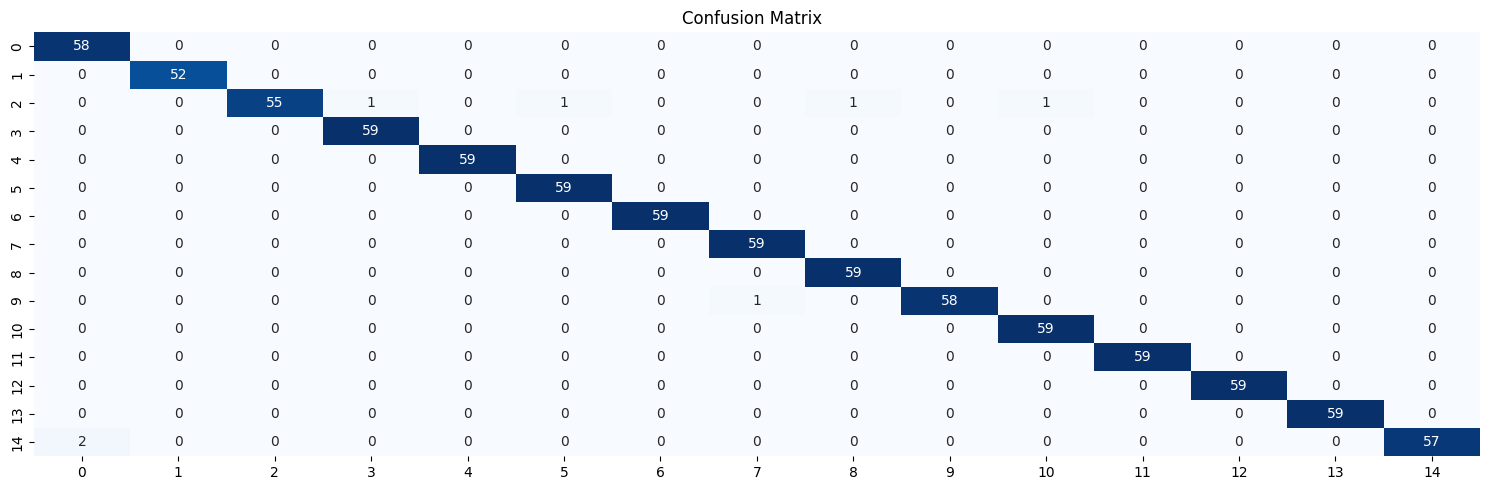

In [21]:
draw_confusion_matrix(confusion_matrix_FC,"Confusion Matrix")

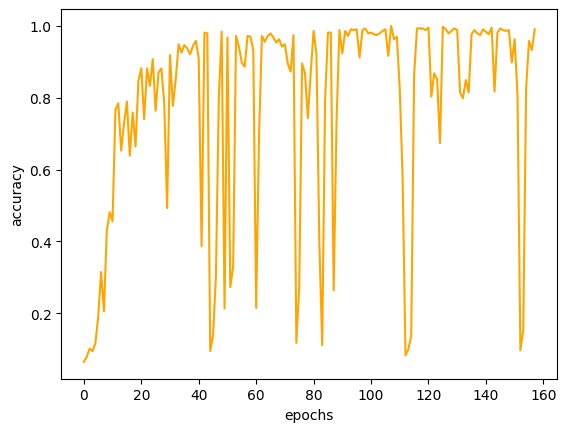

In [22]:
plt.figure()
# plt.plot(history.history['accuracy'], 'g', label='Training Accuracy')
plt.plot(history.history['val_accuracy'], color='orange', label='Validation Accuracy')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.show()

## Save

In [ ]:
# Convert our Keras model to a TFLite flatbuffer file
with open("model.tflite", "wb") as flatbuffer_file:
    flatbuffer_bytes = lce.convert_keras_model(model)
    flatbuffer_file.write(flatbuffer_bytes)